# EN3330 Assignment 03 — Graphs for Lagrangian Duality

This notebook generates the assignment graphs using NumPy and Matplotlib.

Problem: minimize $x^2$ subject to $x\geq1$. Write $h(x)=1-x\leq0$, so $L(\mu,x)=x^2+\mu(1-x)$ with $\mu\geq0$.

Run the cells from top to bottom.

In [8]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['figure.figsize'] = (8, 5)
plt.rcParams['axes.grid'] = True
plt.rcParams['font.size'] = 11


## Graph 1 — Question 1(a): Lagrangian for $\mu=0,1,2,3$

$L(\mu,x)=x^2-\mu x+\mu$. Its minimizer is $x(\mu)=\mu/2$. The dots mark each curve's minimizer.

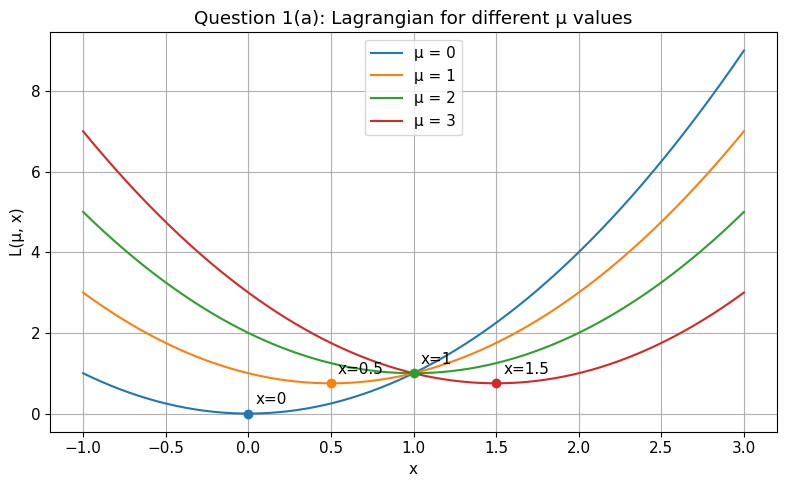

In [9]:
x = np.linspace(-1, 3, 500)
mu_values = [0, 1, 2, 3]

plt.figure()
for mu in mu_values:
    L = x**2 + mu * (1 - x)
    x_min = mu / 2
    L_min = x_min**2 + mu * (1 - x_min)
    plt.plot(x, L, label=f'μ = {mu}')
    plt.scatter([x_min], [L_min], zorder=3)
    plt.annotate(f'x={x_min:g}', (x_min, L_min), xytext=(5, 7), textcoords='offset points')
plt.xlabel('x'); plt.ylabel('L(μ, x)')
plt.title('Question 1(a): Lagrangian for different μ values')
plt.legend(); plt.tight_layout(); plt.show()


## Graph 2 — Question 1(b): Dual function

$d(\mu)=\min_x L(\mu,x)=\mu-\mu^2/4$ for $\mu\geq0$. Its maximum is at $(\mu^*,d^*)=(2,1)$.

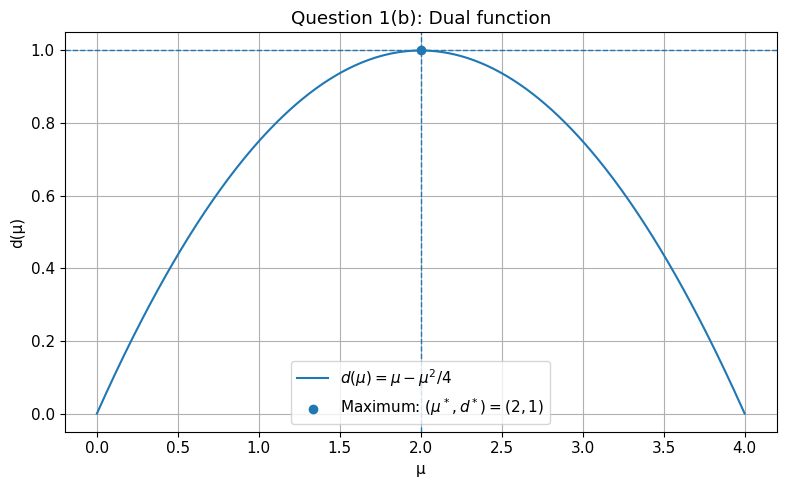

In [10]:
mu = np.linspace(0, 4, 500)
d = mu - mu**2 / 4
plt.figure()
plt.plot(mu, d, label=r'$d(\mu)=\mu-\mu^2/4$')
plt.scatter([2], [1], zorder=3, label=r'Maximum: $(\mu^*,d^*)=(2,1)$')
plt.axvline(2, linestyle='--', linewidth=1); plt.axhline(1, linestyle='--', linewidth=1)
plt.xlabel('μ'); plt.ylabel('d(μ)')
plt.title('Question 1(b): Dual function')
plt.legend(); plt.tight_layout(); plt.show()


## Graph 3 — Question 1(c): Primal function $g(x)$

$g(x)=+\infty$ for $x<1$ and $g(x)=x^2$ for $x\geq1$. Since infinity cannot be displayed directly, the infeasible section is shown schematically at a finite height.

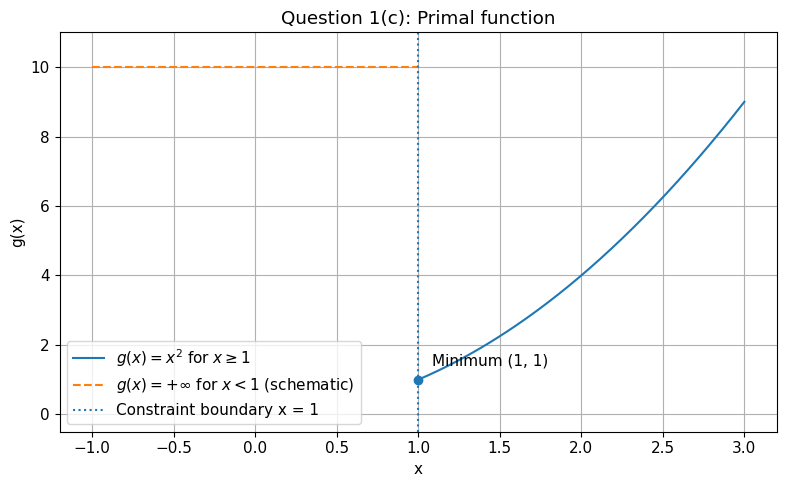

In [11]:
x = np.linspace(-1, 3, 600)
g_feasible = np.where(x >= 1, x**2, np.nan)
plt.figure()
plt.plot(x, g_feasible, label=r'$g(x)=x^2$ for $x\geq1$')
display_height = 10
plt.plot(x[x < 1], np.full(np.sum(x < 1), display_height), linestyle='--',
         label=r'$g(x)=+\infty$ for $x<1$ (schematic)')
plt.axvline(1, linestyle=':', linewidth=1.5, label='Constraint boundary x = 1')
plt.scatter([1], [1], zorder=3)
plt.annotate('Minimum (1, 1)', (1, 1), xytext=(10, 10), textcoords='offset points')
plt.xlabel('x'); plt.ylabel('g(x)')
plt.title('Question 1(c): Primal function')
plt.ylim(-0.5, 11); plt.legend(); plt.tight_layout(); plt.show()


## Graph 4 — Question 2(a)

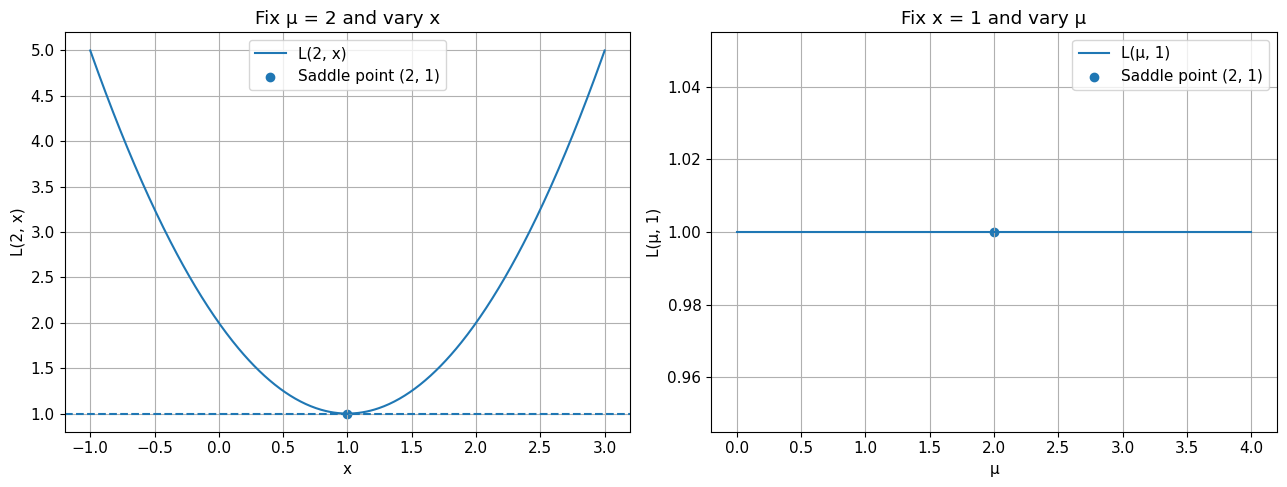

In [12]:
import numpy as np
import matplotlib.pyplot as plt

# Lagrangian
def L(mu, x):
    return x**2 + mu * (1 - x)

# Create values
x = np.linspace(-1, 3, 500)
mu = np.linspace(0, 4, 500)

# Saddle point
mu_star = 2
x_star = 1
L_star = L(mu_star, x_star)

# Create two plots
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Graph 1: Fix mu = 2 and vary x
axes[0].plot(x, L(mu_star, x), label="L(2, x)")
axes[0].scatter(x_star, L_star, label="Saddle point (2, 1)")
axes[0].axhline(L_star, linestyle="--")
axes[0].set_xlabel("x")
axes[0].set_ylabel("L(2, x)")
axes[0].set_title("Fix μ = 2 and vary x")
axes[0].legend()
axes[0].grid(True)

# Graph 2: Fix x = 1 and vary mu
axes[1].plot(mu, L(mu, x_star), label="L(μ, 1)")
axes[1].scatter(mu_star, L_star, label="Saddle point (2, 1)")
axes[1].set_xlabel("μ")
axes[1].set_ylabel("L(μ, 1)")
axes[1].set_title("Fix x = 1 and vary μ")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

## Graph 5 — Question 3(b): Lagrangian against $\mu$ for $x=0,1,2$

For fixed $x$: $L(\mu,0)=\mu$, $L(\mu,1)=1$, and $L(\mu,2)=4-\mu$. The dashed line is the lower envelope of these three selected lines only; it is not the full dual function, which takes the infimum over all real $x$.

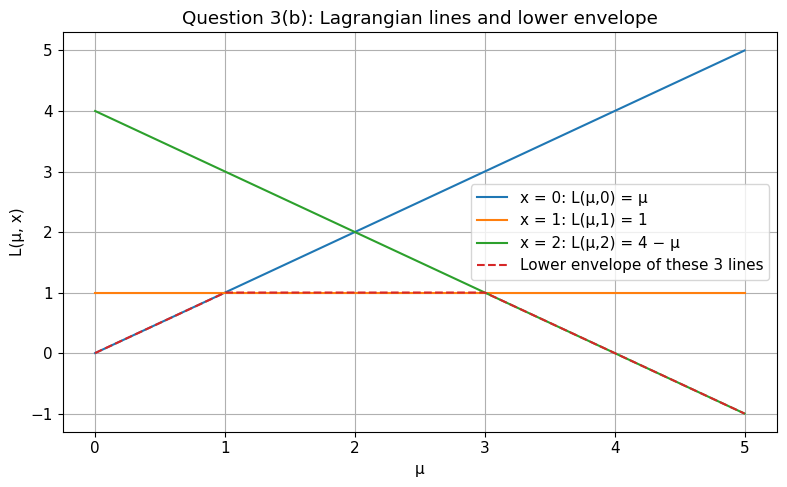

In [13]:
mu = np.linspace(0, 5, 500)
L_x0 = mu
L_x1 = np.ones_like(mu)
L_x2 = 4 - mu
lower_envelope_three = np.minimum(np.minimum(L_x0, L_x1), L_x2)
plt.figure()
plt.plot(mu, L_x0, label='x = 0: L(μ,0) = μ')
plt.plot(mu, L_x1, label='x = 1: L(μ,1) = 1')
plt.plot(mu, L_x2, label='x = 2: L(μ,2) = 4 − μ')
plt.plot(mu, lower_envelope_three, linestyle='--', label='Lower envelope of these 3 lines')
plt.xlabel('μ'); plt.ylabel('L(μ, x)')
plt.title('Question 3(b): Lagrangian lines and lower envelope')
plt.legend(); plt.tight_layout(); plt.show()


## Graph 6 — Actual dual function vs. three-line envelope

The actual dual function considers every real $x$, so it can lie below the envelope formed using only $x=0,1,2$.

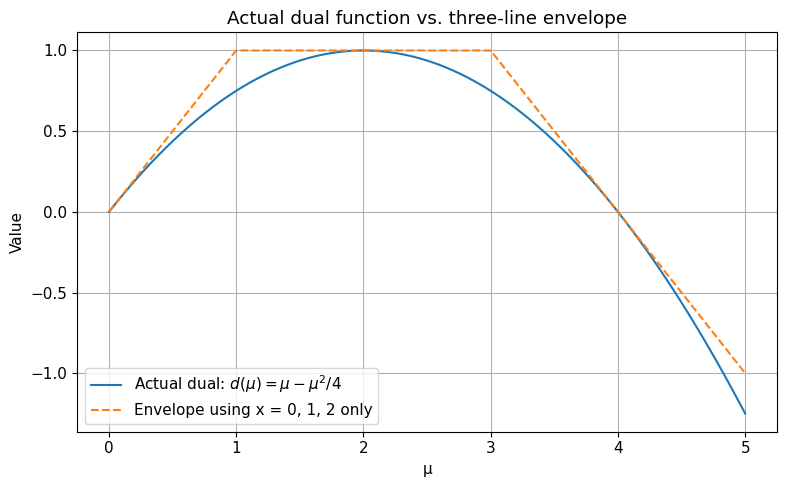

In [14]:
mu = np.linspace(0, 5, 500)
actual_dual = mu - mu**2 / 4
three_line_envelope = np.minimum(np.minimum(mu, np.ones_like(mu)), 4 - mu)
plt.figure()
plt.plot(mu, actual_dual, label=r'Actual dual: $d(\mu)=\mu-\mu^2/4$')
plt.plot(mu, three_line_envelope, linestyle='--', label='Envelope using x = 0, 1, 2 only')
plt.xlabel('μ'); plt.ylabel('Value')
plt.title('Actual dual function vs. three-line envelope')
plt.legend(); plt.tight_layout(); plt.show()
